# One cohort analysis: fluid intelligence and sex in 943 young adults

From the question to the checks of sensitivity, on the continuous structural connectomes of the
HCP Young Adult subjects with a fluid-intelligence score.

- **Question.** Do fluid intelligence -- the number of Penn Matrix Test items answered correctly
  (PMAT24, of 24) -- and sex show in the structural connectome of young adults, where on the
  cortex, and can either be predicted from it?
- **Input.** The cohort's 946 structural connectomes; the open-access traits (sex, the HCP's age
  band, the score); each file's streamline count; FreeSurfer's estimate of intracranial volume;
  and, for one check, head motion in the resting-state scans. The young adults are twins and
  siblings. Which of them belong to one family is restricted HCP data: it is read from outside the
  repository when the notebook runs, only counts drawn from it appear below, and no subject is
  named.
- **Choices**, in the first code cell: the outcome and the covariates, which can be changed while
  the validation stays as it is (families as clusters in every test, whole families in every
  null); the rank of the functional PCA; the false discovery rate; the network-based statistic's
  threshold and draws.
- **Execution.** This notebook, after `scripts/cohort_data.py`, which reads every file once for
  each vertex's connectivity strength and the Desikan-Killiany matrices. The graph measures use
  bctpy, the Brain Connectivity Toolbox's Python port (0.6.1 here); without it, those cells say so
  and skip.
- **Output.** Sections 1 to 6: the cohort; a rank-20 functional PCA; its components tested with
  families as clusters; the test at every vertex; where held-out prediction stands; and the
  results in atlas language, handed on to graph measures and the network-based statistic.
- **Interpretation.** Section 4, and *What this says* at the end.
- **Sensitivity.** Section 7.

With the saved fit, the notebook runs in 7 to 11 minutes on 8 cores, depending on the node, with
about 2 GB of memory at its peak; fitting the components afresh is a batch job of four to five and
a half hours (section 2).

In [1]:
import os

# The graph measures and the network-based statistic run in processes of one thread each: a
# thread count set in the environment would be inherited by every process, and their threads
# would crowd the cores. Set before numpy is imported.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"

import contextlib
import csv
import io
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse.csgraph import connected_components
from scipy.stats import binomtest, skew

import sbci
from sbci.atlas import cortex_mask
from sbci.reduction import Reduction

# The lab's copies on Longleaf; point these at your own files.
ROOT = Path("/work/users/x/y/xya/hcp-ya")
SC = ROOT / "full" / "data"  # each subject's structural connectome, <subject>_sc.h5
TRAITS = ROOT / "open_access_traits.csv"  # subject, sex, age_bin, fluid_intelligence_pmat24
HEAD_SIZE = ROOT / "head_size.csv"  # subject, intracranial volume (FreeSurfer's estimate, litres)
MOTION = ROOT / "fc" / "covariates.csv"  # subject, head motion (resting-state scans), ...
FAMILIES = ROOT / "restricted" / "families.csv"  # restricted HCP data: read here, never shown
MEASURES = ROOT / "cohort" / "measures.npz"  # what scripts/cohort_data.py wrote
FIT = ROOT / "full" / "fpca_rank20_c1.npz"  # the rank-20 fit: reused if present, else made here
PREDICTION = Path("prediction.ipynb")  # the prediction benchmark, saved with its outputs
# The benchmark's further rows, the smoothing control among them, as its run recorded them.
BENCHMARK = Path("/work/users/x/y/xya/paper-open-items/r8-benchmark-5477801.out")

# The choices. The outcome and the covariates can be changed here; the validation stays as it
# is: families as clusters, the correction across components, vertices or regions, and whole
# families in every null.
OUTCOME, LABEL = "fluid_intelligence_pmat24", "fluid intelligence"  # a column of TRAITS, its name
COVARIATES = ["sex", "age band", "streamline count", "intracranial volume"]
RANK = 20  # components of the functional PCA
ALPHA = 0.05  # the false discovery rate
THRESHOLD, DRAWS, SEED = 3.1, 5000, 20261021  # the network-based statistic's t, null draws, seed

# The package's figure style: one blue for the continuous connectome, orange for the atlas.
BLUE, ORANGE, INK, MUTED, RULE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#d9d8d3"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
SURFACE_RAMP = LinearSegmentedColormap.from_list(
    "surface", ["#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
)
plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": RULE,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED,
    "ytick.color": MUTED, "figure.facecolor": "white", "figure.dpi": 110,
})


def surface(values, title, scale=None, threshold=None):
    """A map on fsaverage, as the package's figures are drawn.

    A map with both signs is drawn on a scale centred on zero, blue below and red above; any
    other on the blue ramp. ``scale`` fixes the colour range, so that two maps can be compared;
    without it the map is coloured over its own 2nd to 98th percentile. Values nearer zero than
    ``threshold`` are left uncoloured, so that the cortex shows through.
    """
    signed = bool(np.nanmin(values) < 0 < np.nanmax(values))
    if scale is None:
        scale = tuple(float(v) for v in np.round(np.nanpercentile(values, [2, 98]), 2))
    return sbci.plot_surface(
        values, cmap="coolwarm" if signed else SURFACE_RAMP, symmetric=signed, vmin=scale[0],
        vmax=scale[1], threshold=threshold, title=title, mesh="fsaverage", engine="pyvista",
    )

## 1. The cohort

`load_cohort` takes the folder of SC files and two tables, the open-access traits and the head
sizes, and keeps the subjects with a usable file and an outcome. All 946 files pass its checks and
store their streamline endpoints; the three subjects without a fluid-intelligence score are left
out, which leaves 943, 505 of them women. The covariates are sex; the HCP's age band, entered as
its midpoint in years (23.5, 28, 33 or 37), as the earlier analyses of this cohort entered it;
the streamline count each file records, in millions, 5.5% lower in women on average; and head
size, FreeSurfer's estimated intracranial volume, 1.708 L in men on average against 1.473 L in
women (1.59 standard deviations apart), which correlates with the score at r = 0.25. The 943 are
422 families, so every test below takes the families as clusters. `scripts/cohort_data.py` has
read each file once beforehand, for each vertex's connectivity strength and the Desikan-Killiany
matrix of each subject (sections 4 and 6).

In [2]:
cohort = sbci.load_cohort(SC, table=[TRAITS, HEAD_SIZE],
                          require=[OUTCOME, "sex", "age_bin", "intracranial volume"])
print(cohort.summary())
subjects = cohort.subjects  # the ids, sorted: they pair the tables with the files, never shown
endpoints = sum(row["sc_endpoints"] == 1 for row in cohort.report)
print(f"the report: {len(cohort.report)} subjects, {cohort.n_subjects} in the cohort; {endpoints} "
      "of their files store the streamline endpoints")

streamlines = {row["subject"]: row["sc_streamlines"] for row in cohort.report}
count = np.array([streamlines[s] for s in subjects], dtype=float)
BAND = {"22-25": 23.5, "26-30": 28.0, "31-35": 33.0, "36+": 37.0}  # the HCP's age bands
values = {  # every covariate the models can take, in the cohort's order
    OUTCOME: cohort.column(OUTCOME),
    "sex": (cohort.column("sex") == "F").astype(float),  # 1 for a woman: positive, higher in women
    "age band": np.array([BAND[band] for band in cohort.column("age_bin")]),  # its midpoint, years
    "streamline count": count / 1e6,  # in millions
    "intracranial volume": cohort.column("intracranial volume"),  # in litres
}
women = values["sex"] == 1
score, volume = values[OUTCOME], values["intracranial volume"]
print(f"{int(women.sum())} women and {int((~women).sum())} men; by age band "
      + ", ".join(f"{band} {n}" for band, n in sorted(Counter(cohort.column("age_bin")).items())))
print(f"{LABEL}: {score.min():.0f} to {score.max():.0f}, {score.mean():.1f} on average "
      f"(sd {score.std(ddof=1):.1f})")
print(f"streamline count: {count.min():,.0f} to {count.max():,.0f}; {count[women].mean() / 1e6:.3f} "
      f"million in women and {count[~women].mean() / 1e6:.3f} in men on average, "
      f"{1 - count[women].mean() / count[~women].mean():.1%} fewer in women")
pooled = np.sqrt(((women.sum() - 1) * volume[women].var(ddof=1)
                  + ((~women).sum() - 1) * volume[~women].var(ddof=1)) / (volume.size - 2))
print(f"intracranial volume: {volume[~women].mean():.3f} L in men and {volume[women].mean():.3f} L "
      f"in women on average, {(volume[~women].mean() - volume[women].mean()) / pooled:.2f} pooled "
      f"standard deviations apart; r with {LABEL} {np.corrcoef(volume, score)[0, 1]:+.2f}")

with open(FAMILIES, newline="") as handle:
    family_of = {row["subject"]: row["group"] for row in csv.DictReader(handle)}
family = np.unique([family_of[s] for s in subjects], return_inverse=True)[1]  # codes 0, 1, ...
del family_of
sizes = np.bincount(np.bincount(family))
print(f"{len(subjects)} subjects in {family.max() + 1} families, of "
      + ", ".join(f"{size} ({n})" for size, n in enumerate(sizes) if size and n)
      + " members (how many families)")

with np.load(MEASURES) as saved:
    position = {str(s): k for k, s in enumerate(saved["subjects"])}
    rows = [position[s] for s in subjects]
    strength = saved["strength"][rows]  # each vertex's connectivity strength, a row a subject
    desikan_mass = saved["desikan"][rows]  # each subject's 68 x 68 Desikan-Killiany masses
    area, cortex = saved["area"], saved["cortex"]
    agree = bool(np.array_equal(saved["streamlines"][rows], count))
assert np.array_equal(cortex, cortex_mask())  # the grid's cortex, the medial wall left out
print(f"scripts/cohort_data.py's measures of the {len(rows)}: the strength of {strength.shape[1]:,} "
      f"vertices and a {desikan_mass.shape[1]} x {desikan_mass.shape[2]} Desikan-Killiany matrix "
      f"each; their streamline counts are the files' own: {agree}")

946 subjects seen; 943 in the cohort (sc).
  left out, 3: no value for fluid_intelligence_pmat24
  sc files share: spec_version '0.1.0-draft', grid 'fsaverage-ico4', mask 'medial-wall', area_weights 'vertex-area', normalization 'unit-mass', kernel 'shk', bandwidth 0.005, nu None, streamline_weighting 'none', registration_reference 'fsaverage', pipeline_version 'SBCI_Pipeline endpoints; sbci smoothing', container_version "none (built from the lab's pipeline output)"
the report: 946 subjects, 943 in the cohort; 946 of their files store the streamline endpoints
505 women and 438 men; by age band 22-25 202, 26-30 414, 31-35 318, 36+ 9
fluid intelligence: 4 to 24, 16.9 on average (sd 4.8)
streamline count: 599,553 to 1,071,113; 0.803 million in women and 0.850 in men on average, 5.5% fewer in women
intracranial volume: 1.708 L in men and 1.473 L in women on average, 1.59 pooled standard deviations apart; r with fluid intelligence +0.25
943 subjects in 422 families, of 1 (96), 2 (162), 3 (13

scripts/cohort_data.py's measures of the 943: the strength of 5,124 vertices and a 68 x 68 Desikan-Killiany matrix each; their streamline counts are the files' own: True


## 2. The rank-20 functional PCA

The functional PCA approximates each connectome around the cohort's mean by a sum of separable
components, each one surface map times itself, and gives every subject a score on each. Twenty
components hold 27.3% of the cohort's norm -- the square root of their share of its sum of
squares, which is 7.4% -- and the first four 16.8%: the components are a small part of what varies
between subjects, which matters in section 4. The fit holds all 943 connectomes in memory at once
and takes four to five and a half hours on eight threads with 230 GB (USAGE.md, *Running it on
Longleaf*): a batch job, not a notebook's. So it is saved, as
`scripts/hcp_figures.py --full-cohort` saves it, and reused here; the cell checks that the saved
fit belongs to these subjects in this order, and fits it otherwise.

In [3]:
if FIT.exists():
    with np.load(FIT) as saved:
        if [str(s) for s in saved["subjects"]] != subjects or saved["basis"].shape[1] != RANK:
            raise ValueError(f"{FIT} holds another fit: point FIT at a new file to fit this one")
        reduction = Reduction(
            basis=saved["basis"], scores=saved["scores"], scales=saved["scales"],
            explained=saved["explained"], objective=np.zeros((RANK, 1)),
            mean=saved["mean"] if "mean" in saved.files else None,
        )
        agree = all(np.array_equal(saved[key], value) for key, value in (
            ("female", values["sex"]), ("band", values["age band"]), ("count", count)))
    print(f"reused {FIT.name}: rank {RANK}, fitted to these {len(subjects)} subjects in this order; "
          f"the sex, age band and streamline count saved with it are the cohort's: {agree}")
else:
    from threadpoolctl import threadpool_limits

    print("no saved fit: fitting one, four to five and a half hours on eight threads and 230 GB")
    start = time.time()
    with threadpool_limits(limits=len(os.sched_getaffinity(0))):  # every core the job has
        reduction = sbci.reduce(cohort.paths("sc"), rank=RANK, candidates=1)
    np.savez(FIT, basis=reduction.basis, scores=reduction.scores, scales=reduction.scales,
             explained=reduction.explained, count=count, trait=score, female=values["sex"],
             band=values["age band"], subjects=np.array(subjects), rank=RANK, candidates=1,
             mean=reduction.mean, sbci_version=sbci.__version__, made=time.strftime("%Y-%m-%d %H:%M"))
    print(f"fitted in {time.time() - start:,.0f}s, loading included, and saved as {FIT}")
held = reduction.explained[-1]
print(f"{RANK} components hold {held:.1%} of the cohort's norm, the square root of their "
      f"{held ** 2:.1%} of its sum of squares; the first four hold {reduction.explained[3]:.1%}")

reused fpca_rank20_c1.npz: rank 20, fitted to these 943 subjects in this order; the sex, age band and streamline count saved with it are the cohort's: True
20 components hold 27.3% of the cohort's norm, the square root of their 7.4% of its sum of squares; the first four hold 16.8%


## 3. Localized inference on the components

`local_test` fits each component's scores on the tested covariate and the others, with the
families as clusters -- cluster-robust standard errors over the 422 families, an F test on 1 and
421 degrees of freedom -- and corrects across the twenty components at a false discovery rate of
0.05. Fluid intelligence, given sex, age band, streamline count and intracranial volume, tracks no
component: the closest three, components 12, 13 and 7, all sit at adjusted p = 0.087. Sex, given
fluid intelligence and the other three, shows in 3 of the 20, components 3, 5 and 8, each at
adjusted p = 0.035; without intracranial volume in the model it shows in 13, the strongest at an
adjusted p of 1.1e-7, so head size carries much of the difference between women's components and
men's. The figure shows every component's adjusted p.

fluid intelligence given sex, age band, streamline count and intracranial volume: 0 of 20 components at FDR 0.05 []; the smallest p in components [12, 13, 7], adjusted 0.087, 0.087, 0.087
sex given fluid intelligence, age band, streamline count and intracranial volume: 3 of 20 components at FDR 0.05 [3, 5, 8]; the smallest p in components [3, 8, 5], adjusted 0.035, 0.035, 0.035
sex given fluid intelligence, age band and streamline count: 13 of 20 components at FDR 0.05 [1, 2, 3, 5, 6, 8, 9, 10, 12, 15, 16, 18, 19]; the smallest p in components [16, 3, 5], adjusted 1.1e-07, 0.00025, 0.00052
families as clusters: 422 of them, F on 1 and 421 degrees of freedom
sex, the partial r of the components that pass: component 3 -0.101, component 5 -0.100, component 8 -0.103


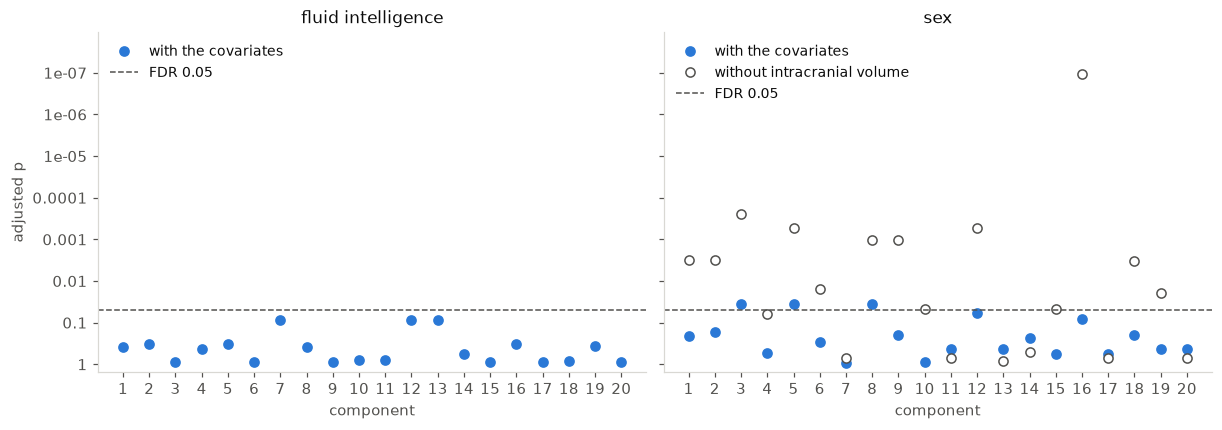

In [4]:
def design(tested, given, use=None):
    """The tested covariate as column 1 -- local_test adds the intercept as column 0 -- and then
    the covariates it is given; ``use`` replaces some covariates' values."""
    use = {**values, **(use or {})}
    return np.column_stack([use[tested], *(use[name] for name in given)])


def signed_r(result):
    """Each column's partial correlation with the tested covariate, signed by its estimate."""
    return np.sign(result.estimate[:, 0]) * np.sqrt(result.partial_r2)


def listed(names):
    """Names in prose, "a", "a and b", "a, b and c", the outcome by its LABEL."""
    names = [LABEL if name == OUTCOME else name for name in names]
    return names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1]


def without(names, left_out):
    return [name for name in names if name != left_out]


def pv(p):
    """A p-value as printed here: three decimals, or two significant digits below 0.01."""
    return f"{p:.2g}" if p < 0.01 else f"{p:.3f}"


def counted(result):
    """The columns significant at the false discovery rate ALPHA, counted from 1."""
    return (result.significant(ALPHA) + 1).tolist()


def closest(result, k=3):
    """The k columns with the smallest p-values, counted from 1, and their adjusted p."""
    order = np.argsort(result.pvalue, kind="stable")[:k]
    return (order + 1).tolist(), ", ".join(pv(p) for p in result.adjusted[order])


OUTCOME_GIVEN = without(COVARIATES, OUTCOME)
SEX_GIVEN = [OUTCOME] + without(COVARIATES, "sex")
NO_VOLUME = without(SEX_GIVEN, "intracranial volume")
component_tests = {}
for label, (tested, given) in {
    f"{LABEL} given {listed(OUTCOME_GIVEN)}": (OUTCOME, OUTCOME_GIVEN),
    f"sex given {listed(SEX_GIVEN)}": ("sex", SEX_GIVEN),
    f"sex given {listed(NO_VOLUME)}": ("sex", NO_VOLUME),
}.items():
    result = sbci.local_test(reduction.scores, design(tested, given), terms=[1], groups=family)
    component_tests[label] = result
    which, adjusted = closest(result)
    print(f"{label}: {len(counted(result))} of {RANK} components at FDR {ALPHA} {counted(result)}; "
          f"the smallest p in components {which}, adjusted {adjusted}")
print(f"families as clusters: {result.groups} of them, F on {result.numerator_dof} and "
      f"{result.interval_dof} degrees of freedom")
outcome_test = component_tests[f"{LABEL} given {listed(OUTCOME_GIVEN)}"]
sex_test = component_tests[f"sex given {listed(SEX_GIVEN)}"]
r = signed_r(sex_test)
print("sex, the partial r of the components that pass: "
      + ", ".join(f"component {k + 1} {r[k]:+.3f}" for k in sex_test.significant(ALPHA)))

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, constrained_layout=True)
number = np.arange(1, RANK + 1)
smallest = min(np.nanmin(result.adjusted) for result in component_tests.values())
for axis, title, series in (
    (left, LABEL, [(outcome_test, BLUE, "with the covariates")]),
    (right, "sex", [(sex_test, BLUE, "with the covariates"),
                    (component_tests[f"sex given {listed(NO_VOLUME)}"], MUTED,
                     "without intracranial volume")]),
):
    for result, colour, name in series:
        axis.plot(number, result.adjusted, "o", color=colour, markersize=6, label=name,
                  markerfacecolor=colour if colour == BLUE else "white")
    axis.axhline(ALPHA, color=MUTED, linewidth=1, linestyle="--", label=f"FDR {ALPHA}")
    axis.set_title(title, fontsize=11)
    axis.set_xticks(number)
    axis.set_xlabel("component")
    axis.legend(frameon=False, fontsize=9, loc="upper left")
left.set_yscale("log")
left.set_ylim(1.5, smallest / 10)  # inverted: the smallest adjusted p near the top
left.yaxis.set_major_locator(plt.LogLocator(base=10, numticks=12))
left.yaxis.set_minor_locator(plt.NullLocator())
left.yaxis.set_major_formatter(plt.FuncFormatter(lambda p, _: f"{p:g}"))
left.set_ylabel("adjusted p")
plt.show()

The map below sums the fitted difference between women and men over the three components, at
every vertex, relative to its largest value. It peaks in the right cuneus, where connectivity is
higher in men, with the right pericalcarine cortex next; a smaller patch of the right lateral
occipital cortex is higher in women (to +0.282 of the peak), and nothing on the left reaches a
twentieth of the peak. It describes what those three components carry, which section 4 sets
beside the test at each vertex.

the effect over components 3, 5 and 8 peaks at a vertex of RH_cuneus, higher in men; 4.3% of the cortex reaches a twentieth of the peak, the left hemisphere at most 0.046 of it
its largest value above zero, +0.282 of the peak, is at a vertex of RH_lateraloccipital
its means over the Desikan-Killiany regions: the lowest RH_cuneus -0.661, RH_pericalcarine -0.327, RH_superiorparietal -0.078; the highest LH_superiorparietal +0.002


[fetch_surf_fsaverage] Dataset directory found: /nas/longleaf/home/xya/nilearn_data/fsaverage


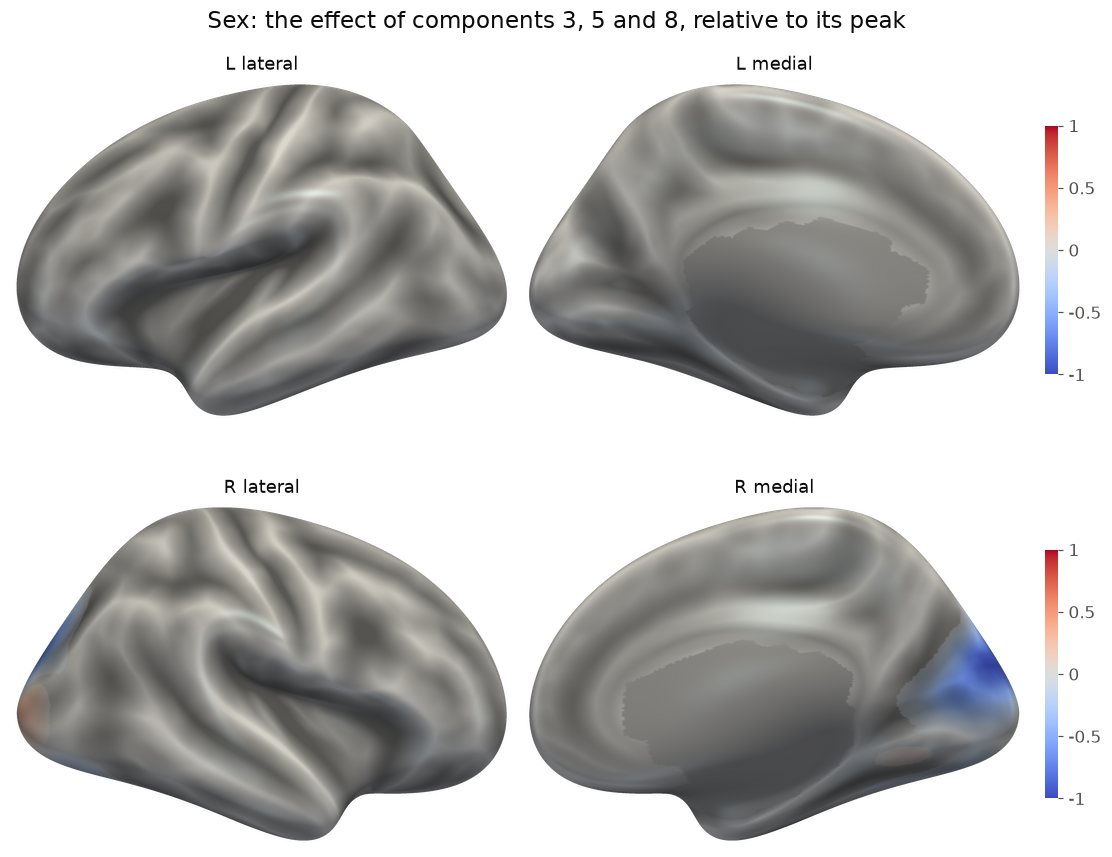

In [5]:
desikan = sbci.load_atlas("Desikan")
names, labels = list(desikan.names), np.asarray(desikan.labels)
effect = sex_test.effect_map(reduction, alpha=ALPHA)  # the components that pass, and no others
if not np.abs(effect[cortex]).max() > 0:
    raise ValueError("no sex component passes, so there is no effect to map")
relative = np.where(cortex, effect / np.abs(effect[cortex]).max(), np.nan)
means = sbci.region_means(relative, desikan, area=area)  # area-weighted, over each region
peak = int(np.nanargmax(np.abs(relative)))
half = cortex.size // 2  # the left hemisphere's vertices come first
print(f"the effect over components {listed([str(k) for k in counted(sex_test)])} peaks at a vertex "
      f"of {names[labels[peak] - 1]}, {'higher in women' if relative[peak] > 0 else 'higher in men'}; "
      f"{np.mean(np.abs(relative[cortex]) >= 0.05):.1%} of the cortex reaches a twentieth of the peak, "
      f"the left hemisphere at most {np.nanmax(np.abs(relative[:half])):.3f} of it")
top = int(np.nanargmax(relative))
print(f"its largest value above zero, {relative[top]:+.3f} of the peak, is at a vertex of "
      f"{names[labels[top] - 1]}")
order = np.argsort(means)
print("its means over the Desikan-Killiany regions: the lowest "
      + ", ".join(f"{names[k]} {means[k]:+.3f}" for k in order[:3])
      + f"; the highest {names[order[-1]]} {means[order[-1]]:+.3f}")
figure = surface(relative, f"Sex: the effect of components {listed([str(k) for k in counted(sex_test)])}, "
                 "relative to its peak", scale=(-1.0, 1.0), threshold=0.05)

## 4. The test at every vertex

Each vertex's connectivity strength -- its density summed over the other endpoint -- is tested in
the same models, the families as clusters, with the correction across the 4,685 cortical
vertices; the medial wall's 439 hold no connectivity and cannot be tested. Sex differs at 433
vertices, 327 of them higher in women and 106 in men, 214 on the left and 219 on the right, with
partial correlations of 0.089 to 0.261 in magnitude. The most lie in the insula: 57 of the right
insula's 82 vertices and 33 of the left's 80, every one higher in women. For fluid intelligence
the vertices agree with the components: tested alone, the score shows at 113 vertices; given sex,
age band and streamline count, at 26; and with intracranial volume as well, at none (smallest
adjusted p 0.086).

For sex the two views disagree. The components put the difference in the right medial occipital
cortex, higher in men; the vertices put most of it in the insulae, higher in women. Over the
cortex the effect map correlates with the vertex test's partial correlations at r = 0.15. The map
reaches a tenth of its peak at 113 vertices below zero and 20 above, and of the 433 vertices where
sex differs, 21 lie among the first and none among the second. A component map describes what
those components carry, a small part of the cohort's variation, not where the groups differ.

4,685 of the grid's 5,124 vertices can be tested, the cortex: the medial wall's 439 hold no connectivity
sex given fluid intelligence, age band, streamline count and intracranial volume: 433 vertices at FDR 0.05, 327 higher in women and 106 in men; 214 on the left and 219 on the right; |partial r| 0.089 to 0.261
  the right insula: 57 of its 82 vertices, 57 of them higher in women
  the left insula: 33 of its 80 vertices, 33 of them higher in women


fluid intelligence alone: 113 vertices at FDR 0.05, strength rising with the score at 42


fluid intelligence given sex, age band and streamline count: 26 vertices at FDR 0.05, strength rising with the score at 19


fluid intelligence given sex, age band, streamline count and intracranial volume: 0 vertices at FDR 0.05; the smallest adjusted p 0.086
the components' effect map against the vertex test's partial r, over the cortex: r = +0.15
the map reaches a tenth of its peak at 113 vertices below zero (higher in men) and 20 above; of the 433 vertices where sex differs, 21 lie among the first and 0 among the second


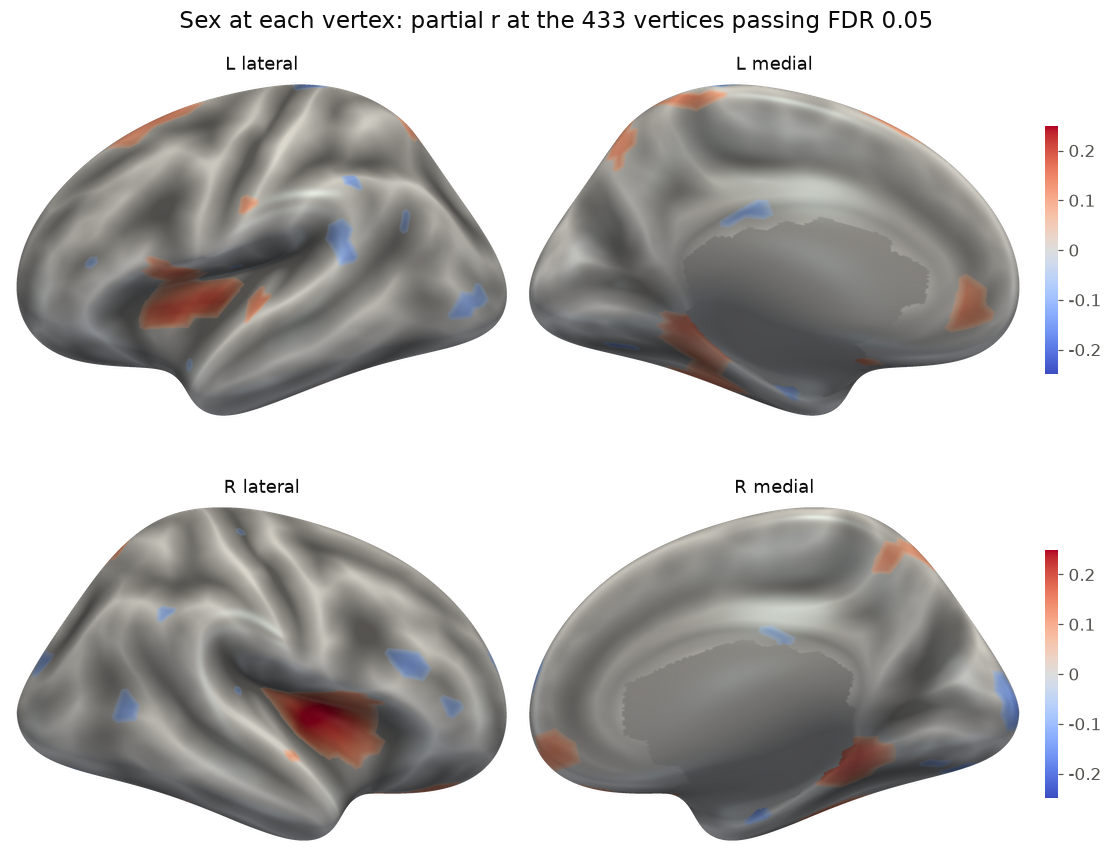

In [6]:
vertex_sex = sbci.local_test(strength, design("sex", SEX_GIVEN), terms=[1], groups=family)
testable = np.isfinite(vertex_sex.pvalue)
print(f"{int(testable.sum()):,} of the grid's {testable.size:,} vertices can be tested, the cortex: "
      f"the medial wall's {int((~testable).sum())} hold no connectivity")
hit = np.zeros(cortex.size, bool)
hit[vertex_sex.significant(ALPHA)] = True
r_sex = signed_r(vertex_sex)
higher = hit & (r_sex > 0)
print(f"sex given {listed(SEX_GIVEN)}: {int(hit.sum())} vertices at FDR {ALPHA}, {int(higher.sum())} "
      f"higher in women and {int((hit & (r_sex < 0)).sum())} in men; {int(hit[:half].sum())} on the "
      f"left and {int(hit[half:].sum())} on the right; |partial r| {np.abs(r_sex[hit]).min():.3f} to "
      f"{np.abs(r_sex[hit]).max():.3f}")
for side, word in (("RH", "right"), ("LH", "left")):
    inside = labels == names.index(f"{side}_insula") + 1
    print(f"  the {word} insula: {int((hit & inside).sum())} of its {int(inside.sum())} vertices, "
          f"{int((higher & inside).sum())} of them higher in women")

outcome_vertices = {}
for label, given in (
    ("alone", []),
    (f"given {listed(without(OUTCOME_GIVEN, 'intracranial volume'))}",
     without(OUTCOME_GIVEN, "intracranial volume")),
    (f"given {listed(OUTCOME_GIVEN)}", OUTCOME_GIVEN),
):
    result = sbci.local_test(strength, design(OUTCOME, given), terms=[1], groups=family)
    outcome_vertices[label] = result
    found = result.significant(ALPHA)
    rising = int((signed_r(result)[found] > 0).sum())
    print(f"{LABEL} {label}: {found.size} vertices at FDR {ALPHA}"
          + (f", strength rising with the score at {rising}" if found.size
             else f"; the smallest adjusted p {np.nanmin(result.adjusted):.3f}"))

on = cortex & np.isfinite(r_sex)
below, above = cortex & (relative <= -0.1), cortex & (relative >= 0.1)
print(f"the components' effect map against the vertex test's partial r, over the cortex: r = "
      f"{np.corrcoef(relative[on], r_sex[on])[0, 1]:+.2f}")
print(f"the map reaches a tenth of its peak at {int(below.sum())} vertices below zero (higher in "
      f"men) and {int(above.sum())} above; of the {int(hit.sum())} vertices where sex differs, "
      f"{int((hit & below).sum())} lie among the first and {int((hit & above).sum())} among the second")

largest = float(np.round(np.abs(r_sex[hit]).max() / 0.05) * 0.05)  # the colour scale, in 0.05s
figure = surface(np.where(cortex, np.where(hit, r_sex, 0.0), np.nan),
                 f"Sex at each vertex: partial r at the {int(hit.sum())} vertices passing FDR {ALPHA}",
                 scale=(-largest, largest), threshold=0.5 * np.abs(r_sex[hit]).min())

## 5. Held-out prediction

Whether either trait can be predicted from the connectome is the benchmark's question, and this
notebook does not repeat it. `notebooks/prediction.ipynb` draws 300 of these young adults, deals
their 134 families whole to five folds, fits everything -- the functional PCA's basis among it --
inside the training folds and scores each fold on its own. Its saved outputs, read below, say that
sex is predicted mostly by head size, brain-mask volume and streamline count alone reaching an AUC
of 0.920 against 0.662 for the continuous components and 0.865 for the Schaefer-200 regions, of
which only the regions add to head size (+0.034, permutation p 0.002); and that neither connectome
predicts fluid intelligence detectably (r = 0.039 and 0.044, permutation p 0.333 and 0.323).

In [7]:
with open(PREDICTION) as handle:
    benchmark = json.load(handle)
printed = [line for cell in benchmark["cells"] if cell["cell_type"] == "code"
           for output in cell.get("outputs", []) if output.get("output_type") == "stream"
           for line in "".join(output["text"]).splitlines()]
print(f"{PREDICTION}, as saved:")
for line in printed:
    if (line.startswith(("300 subjects", "5 folds")) or "chosen:" in line
            or "permutation p" in line):
        print("  " + line.split("; chosen")[0].strip())

prediction.ipynb, as saved:
  300 subjects in 134 families, of 1 (27), 2 (56), 3 (43), 4 (8) members (how many families)
  5 folds of [60, 60, 60, 60, 60] subjects; no family is split between two
  head size and streamlines     AUC 0.920 (95% interval 0.881 to 0.956)
  continuous                    AUC 0.662 (95% interval 0.593 to 0.737)
  continuous, with head size    AUC 0.909 (95% interval 0.858 to 0.952)
  Schaefer-200                  AUC 0.865 (95% interval 0.819 to 0.907)
  Schaefer-200, with head size  AUC 0.954 (95% interval 0.932 to 0.975)
  sex, age band, head size, streamlines r  0.335 (95% interval  0.218 to  0.438)
  continuous                            r  0.039 (95% interval -0.080 to  0.155)
  continuous, with those                r  0.290 (95% interval  0.170 to  0.395)
  Schaefer-200                          r  0.044 (95% interval -0.083 to  0.164)
  Schaefer-200, with those              r  0.318 (95% interval  0.195 to  0.421)
  sex, age band, head size, streamlines

## 6. In atlas language, and handed on to standard tools

A result on the continuous connectome can be reported in any atlas afterwards, by counting its
vertices region by region, and the same files give the regional matrices that graph tools take.

### The vertex test by region

Counted by Desikan-Killiany region, the 433 vertices lie in 49 of the 68 regions. The insulae hold
a fifth of them (90, 20.8%), every one higher in women; then come the left fusiform and left
superior frontal (21 each), the left superior parietal and right lateral orbitofrontal (17 each),
the left pars opercularis (16) and both parahippocampal gyri (14 each), all higher in women, while
the right lateral occipital (14) and left supramarginal (12) are higher in men. The occipital
regions hold 53 of the vertices, 36 of them higher in men; the medial temporal ones 69, 60 of them
higher in women.

The same test on the 68 regions, each region's strength the area-weighted mean of its vertices',
finds 15 regions, 9 higher in women, the right insula strongest (partial r +0.231), then the right
parahippocampal gyrus (+0.140) and the left insula (+0.133). It misses the vertices' differences
in 16 regions where five or more vertices differ, the left fusiform's 21 among them, and averages
over 9 regions whose vertices differ both ways. In these terms the three components' map says
something else again: -0.661 of its peak over the right cuneus, -0.327 over the right
pericalcarine and -0.078 over the right superior parietal cortex, and within 0.04 of zero
everywhere else, the insulae included; across the 68 regions its means correlate with the regional
test's partial correlations at r = 0.25. For fluid intelligence no region passes, by its vertices
or by its mean strength: the closest is the right superior frontal region, with a partial r of
+0.102, then the left superior temporal (-0.098), both at an adjusted p of 0.079.

the 433 vertices lie in 49 of the 68 regions; the two insulae hold 90 (20.8%). The regions holding the most, higher in women / in men, of the region's vertices:
  RH_insula                   57 /   0 of 82
  LH_insula                   33 /   0 of 80
  LH_fusiform                 21 /   0 of 75
  LH_superiorfrontal          21 /   0 of 190
  LH_superiorparietal         17 /   0 of 162
  RH_lateralorbitofrontal     17 /   0 of 69
  LH_parsopercularis          16 /   0 of 49
  LH_parahippocampal          14 /   0 of 28
  RH_fusiform                 11 /   3 of 73
  RH_lateraloccipital          0 /  14 of 92
  RH_parahippocampal          14 /   0 of 28
  LH_supramarginal             0 /  12 of 136
the occipital regions (lateraloccipital, cuneus, pericalcarine, lingual): 53 vertices, 17 higher in women and 36 in men
the medial temporal regions (parahippocampal, entorhinal, fusiform, temporalpole): 69 vertices, 60 higher in women and 9 in men

the 68 regions' mean strength, the same test: 1

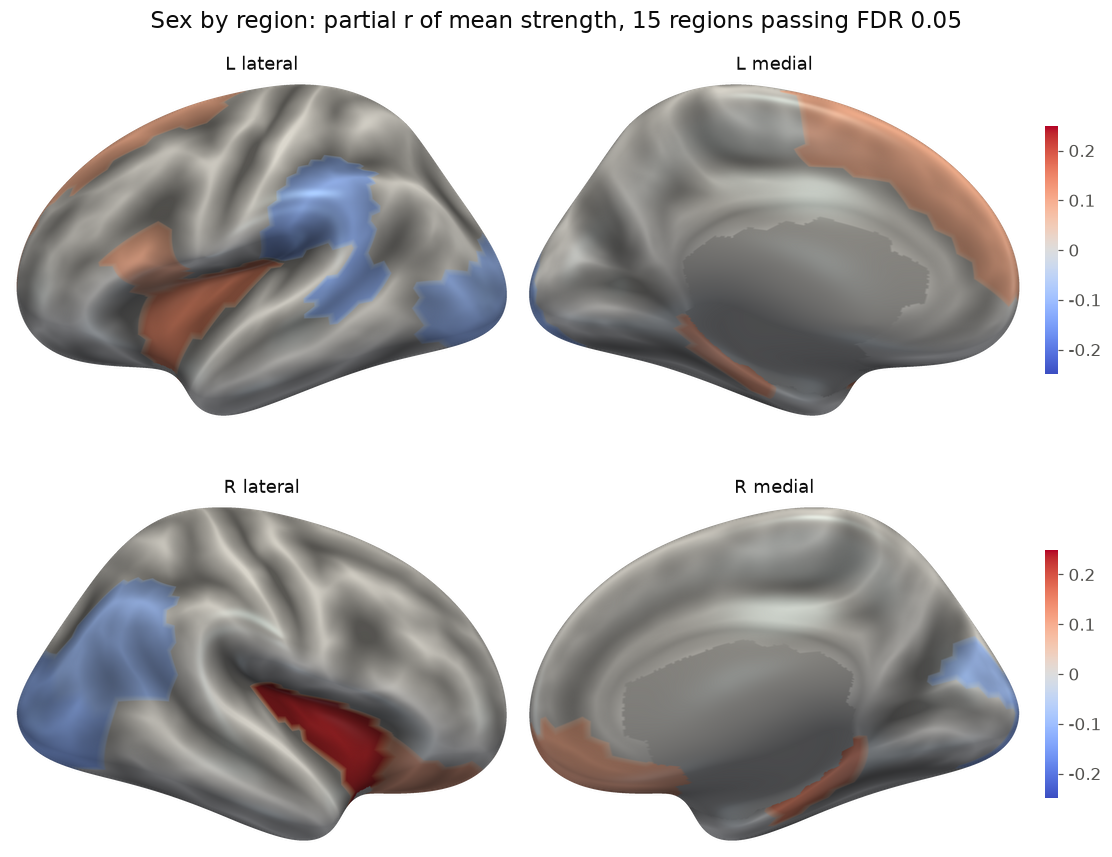

In [8]:
def by_region(hits, r):
    """Each region's significant vertices, (name, positive, negative, vertices), the most first."""
    rows = []
    for k, name in enumerate(names):
        inside = labels == k + 1
        up, down = int((hits & inside & (r > 0)).sum()), int((hits & inside & (r < 0)).sum())
        if up or down:
            rows.append((name, up, down, int(inside.sum())))
    return sorted(rows, key=lambda row: (-(row[1] + row[2]), row[0]))


regions_hit = by_region(hit, r_sex)
insulae = sum(up + down for name, up, down, _ in regions_hit if name.endswith("_insula"))
print(f"the {int(hit.sum())} vertices lie in {len(regions_hit)} of the {len(names)} regions; the two "
      f"insulae hold {insulae} ({insulae / hit.sum():.1%}). The regions holding the most, higher in "
      "women / in men, of the region's vertices:")
for name, up, down, size in regions_hit[:12]:
    print(f"  {name:26s} {up:3d} / {down:3d} of {size}")
LOBES = {"occipital": ("lateraloccipital", "cuneus", "pericalcarine", "lingual"),
         "medial temporal": ("parahippocampal", "entorhinal", "fusiform", "temporalpole")}
for lobe, members in LOBES.items():
    numbers = [names.index(f"{hemi}_{member}") + 1 for hemi in ("LH", "RH") for member in members]
    inside = hit & np.isin(labels, numbers)
    print(f"the {lobe} regions ({', '.join(members)}): {int(inside.sum())} vertices, "
          f"{int((inside & (r_sex > 0)).sum())} higher in women and "
          f"{int((inside & (r_sex < 0)).sum())} in men")

regional = sbci.region_means(strength, desikan, area=area)  # each region's mean strength
region_sex = sbci.local_test(regional, design("sex", SEX_GIVEN), terms=[1], groups=family)
r_region = signed_r(region_sex)
passing = sorted(region_sex.significant(ALPHA), key=lambda k: region_sex.pvalue[k])
counts = {name: (up, down) for name, up, down, _ in regions_hit}
print(f"\nthe {len(names)} regions' mean strength, the same test: {len(passing)} at FDR {ALPHA}, "
      f"{int((r_region[passing] > 0).sum())} higher in women; partial r, adjusted p, and the region's "
      "vertices that differ, higher in women / in men:")
for k in passing:
    up, down = counts.get(names[k], (0, 0))
    print(f"  {names[k]:26s} {r_region[k]:+.3f}  {pv(region_sex.adjusted[k]):7s} {up} / {down} of "
          f"{int((labels == k + 1).sum())}")
missed = [name for name, up, down, _ in regions_hit if names.index(name) not in passing and up + down >= 5]
mixed = [name for name, up, down, _ in regions_hit if up and down]
print(f"regions it misses although 5 or more of their vertices differ: {len(missed)}; regions whose "
      f"vertices differ both ways: {len(mixed)}")

big = np.abs(means) >= 0.05
print(f"\nthe components' effect map, by region: {int(big.sum())} region means reach a twentieth of "
      "its peak, " + ", ".join(f"{names[k]} {means[k]:+.3f}" for k in np.argsort(means) if big[k])
      + f"; the others lie within {np.abs(means[~big]).max():.3f} of zero, the insulae at "
      + " and ".join(f"{means[names.index(f'{side}_insula')]:+.3f}" for side in ("LH", "RH")))
print(f"across the {len(names)} regions, the map's means against the regional test's partial r: "
      f"r = {np.corrcoef(means, r_region)[0, 1]:+.2f}")

region_outcome = sbci.local_test(regional, design(OUTCOME, OUTCOME_GIVEN), terms=[1], groups=family)
r = signed_r(region_outcome)
print(f"\n{LABEL} given {listed(OUTCOME_GIVEN)}: {region_outcome.significant(ALPHA).size} regions at "
      f"FDR {ALPHA}, from {outcome_vertices[f'given {listed(OUTCOME_GIVEN)}'].significant(ALPHA).size} "
      "vertices; the smallest p: " + "; ".join(
          f"{names[k]} partial r {r[k]:+.3f}, adjusted p {pv(region_outcome.adjusted[k])}"
          for k in np.argsort(region_outcome.pvalue, kind="stable")[:3]))

region_map = np.where(cortex, 0.0, np.nan)
for k in passing:
    region_map[labels == k + 1] = r_region[k]
figure = surface(region_map, f"Sex by region: partial r of mean strength, {len(passing)} regions passing "
                 f"FDR {ALPHA}", scale=(-largest, largest), threshold=0.5 * np.abs(r_sex[hit]).min())

### Graph measures, through bctpy

The 943 Desikan-Killiany mass matrices go to bctpy as any regional matrix would, with the
within-region mass on the diagonal taken out, since graph measures assume no self-connections; it
is a median 32.3% of a connectome's mass. Each subject's node strength (`strengths_und`), global
efficiency and characteristic path length from shortest paths through lengths 1/w
(`distance_wei`, `charpath`), mean weighted clustering (`clustering_coef_wu`, on the matrix scaled
to its largest entry) and modularity (`community_louvain` at gamma 1, the best of 100 seeded runs)
are tested like the components, families as clusters, correcting across the four global measures
and across the 68 regions. Neither trait shows in any global measure: for sex the adjusted p run
from 0.547 to 0.658, for fluid intelligence from 0.615 to 0.867. Node strength differs by sex in 19
regions, 16 of them higher in women, the right insula first (partial r +0.241, adjusted p 1.1e-10),
and falls with fluid intelligence in one, the left superior temporal gyrus (-0.121, adjusted p
0.0087), which the test of mean strength above does not pass: node strength is a region's whole
mass to the other regions, which grows with its size, where mean strength is a density. The
weights are shares of a unit mass, so efficiency and path length carry those units.

In [9]:
try:
    import bct  # bctpy, the Brain Connectivity Toolbox's Python port: pip install bctpy
except ImportError:
    bct = None
RUNS = 100  # Louvain runs a subject, seeded 0 to 99; the best Q is kept
GLOBAL = {"efficiency": "global efficiency", "path_length": "characteristic path length",
          "clustering": "mean clustering coefficient", "modularity": "modularity Q"}


def graph_measures(mass):
    """One subject's graph measures, from its Desikan-Killiany masses without the diagonal."""
    W = np.array(mass, dtype=np.float64)
    np.fill_diagonal(W, 0.0)  # the within-region mass: graph measures take no self-connections
    D, _ = bct.distance_wei(bct.weight_conversion(W, "lengths"))  # shortest paths, lengths 1/w
    path_length, efficiency, *_ = bct.charpath(D, include_diagonal=False, include_infinite=False)
    scaled = bct.weight_conversion(W, "normalize")  # divided by its largest entry
    runs = [bct.community_louvain(scaled, gamma=1, seed=seed) for seed in range(RUNS)]
    q = np.array([quality for _, quality in runs])
    return dict(strength=bct.strengths_und(W), efficiency=efficiency, path_length=path_length,
                clustering=bct.clustering_coef_wu(scaled).mean(), modularity=q.max(),
                modules=int(runs[int(q.argmax())][0].max()), reached=int(np.sum(q >= q.max() - 1e-12)),
                connected=bool(np.isfinite(D).all()), within=np.trace(mass) / mass.sum())


if bct is None:
    print("bctpy is not installed (pip install bctpy): the graph measures are skipped")
else:
    start = time.time()
    computed = Parallel(n_jobs=-1, batch_size=4)(delayed(graph_measures)(m) for m in desikan_mass)
    graph = {key: np.array([c[key] for c in computed]) for key in computed[0]}
    print(f"{len(computed)} subjects' graph measures in {time.time() - start:.0f}s; every graph "
          f"connected: {bool(graph['connected'].all())}; the diagonal, taken out, held a median "
          f"{np.median(graph['within']):.1%} of the mass ({graph['within'].min():.1%} to "
          f"{graph['within'].max():.1%})")
    for key, name in GLOBAL.items():
        low, middle, high = np.percentile(graph[key], [2.5, 50, 97.5])
        print(f"  {name:28s} median {middle:.4g} (2.5th to 97.5th percentile {low:.4g} to {high:.4g})")
    print(f"  Louvain: {graph['modules'].min()} to {graph['modules'].max()} modules; the best Q "
          f"reached by {graph['reached'].min()} to {graph['reached'].max()} of the {RUNS} runs "
          f"(median {np.median(graph['reached']):.0f})")
    table = np.column_stack([graph[key] for key in GLOBAL])
    for target, tested, given in (("sex", "sex", SEX_GIVEN), (LABEL, OUTCOME, OUTCOME_GIVEN)):
        overall = sbci.local_test(table, design(tested, given), terms=[1], groups=family)
        print(f"{target}, the four global measures (FDR across them): "
              + "; ".join(f"{name} {r:+.3f}, adjusted p {pv(p)}" for name, r, p in
                          zip(GLOBAL.values(), signed_r(overall), overall.adjusted, strict=True)))
        node = sbci.local_test(graph["strength"], design(tested, given), terms=[1], groups=family)
        r = signed_r(node)
        found = sorted(node.significant(ALPHA), key=lambda k: node.pvalue[k])
        word = "higher in women" if tested == "sex" else "rising with the score"
        print(f"{target}, node strength (FDR across the {len(names)} regions): {len(found)} regions, "
              f"{int((r[found] > 0).sum())} of them {word}")
        for k in found:
            print(f"  {names[k]:26s} partial r {r[k]:+.3f}, adjusted p {pv(node.adjusted[k])}")

943 subjects' graph measures in 108s; every graph connected: True; the diagonal, taken out, held a median 32.3% of the mass (26.5% to 40.8%)
  global efficiency            median 0.0004962 (2.5th to 97.5th percentile 0.0004485 to 0.0005323)
  characteristic path length   median 3588 (2.5th to 97.5th percentile 3031 to 4831)
  mean clustering coefficient  median 0.004263 (2.5th to 97.5th percentile 0.002956 to 0.006881)
  modularity Q                 median 0.4592 (2.5th to 97.5th percentile 0.4215 to 0.5378)
  Louvain: 3 to 6 modules; the best Q reached by 1 to 100 of the 100 runs (median 12)
sex, the four global measures (FDR across them): global efficiency +0.031, adjusted p 0.547; characteristic path length -0.031, adjusted p 0.547; mean clustering coefficient -0.016, adjusted p 0.658; modularity Q +0.032, adjusted p 0.547
sex, node strength (FDR across the 68 regions): 19 regions, 16 of them higher in women
  RH_insula                  partial r +0.241, adjusted p 1.1e-10
  LH_medi

### The network-based statistic, with whole families in the null

The network-based statistic (Zalesky, Fornito and Bullmore 2010, NeuroImage 53:1197) tests the
region pairs as networks. At each of
the 2,278 pairs, taken as log10(mass + 1e-9), the benchmark's transform of regional features, a
linear model with the covariates gives a t statistic for the tested term, each direction on its
own; the pairs past t = 3.1 are joined into connected components, and a component's extent is its
number of pairs. The null is 5,000 Freedman-Lane draws, each flipping the signs of whole families'
residuals under the model without the tested term, adding that model's fit back and refitting
(Winkler et al. 2014, NeuroImage 92:381). Sign flipping assumes that the families are independent
of one another and that each family's errors are symmetric; it needs no exchangeability within a
family, so twins and other siblings may resemble one another differently. The residuals here are
skewed (median skewness -0.46): the 8.9% of pair masses that are zero sit at the logarithm's floor,
3.6 decades below the median of the rest. The null control below checks the error rate anyway.

Stronger in women: one network of 343 pairs over 67 regions, the insulae and orbitofrontal cortex
its hubs (family-wise p < 0.0002: none of the 5,000 draws reached it). Stronger in men: 60 pairs
around lateral occipital and parietal cortex, all but two within a hemisphere (p = 0.002), and 7
more that do not pass (p = 0.0722), in the left temporal lobe, as the next cell describes them. For
fluid intelligence nothing passes: the largest component, 6 pairs rising with the score, has
p = 0.0804.

In [10]:
UPPER = np.triu_indices(len(names), 1)
edges = np.log10(desikan_mass[:, UPPER[0], UPPER[1]] + 1e-9)  # the region pairs, as log mass
hemisphere = np.array([name[:2] for name in names])  # LH or RH
THRESHOLDS = (2.5, THRESHOLD, 3.5)  # the primary threshold and two beside it, from the same draws
DIRECTIONS = {"sex": ((1, "women > men"), (-1, "men > women")),
              LABEL: ((1, "rising with the score"), (-1, "falling with it"))}
MODELS = {"sex": ("sex", SEX_GIVEN), LABEL: (OUTCOME, OUTCOME_GIVEN)}


class Glm:
    """The least-squares t statistic of one design column at every edge, from residuals.

    A surrogate keeps the nuisance model's fit and changes its residuals E alone, so its t does
    too: with X = QR, the tested coefficient is r'Q'E (r' the tested row of R^-1) and the residual
    sum of squares |E|^2 - |Q'E|^2. Flipping or permuting E is then flipping or permuting Q's rows,
    and |E|^2 stays as it is.
    """

    def __init__(self, X, effect=1):
        X = np.asarray(X, dtype=np.float64)
        self.Q, R = np.linalg.qr(X)
        self.row = np.linalg.inv(R)[effect]
        self.v = float(self.row @ self.row)  # (X'X)^-1 at the tested column
        self.dof = X.shape[0] - X.shape[1]
        self.Qz = np.linalg.qr(np.delete(X, effect, axis=1))[0]

    def residuals(self, Y):
        """The residuals of the nuisance model: the design without the tested column."""
        return Y - self.Qz @ (self.Qz.T @ Y)

    def t(self, E, total, Q=None):
        """The t at every edge for residuals E, whose sums of squares are ``total``."""
        A = (self.Q if Q is None else Q).T @ E
        return (self.row @ A) / np.sqrt((total - np.einsum("ij,ij->j", A, A)) / self.dof * self.v)


def networks(t, threshold):
    """The connected components of the edges past the threshold, as their edges, largest first."""
    supra = t > threshold
    if not supra.any():
        return []
    adjacency = np.zeros((len(names), len(names)))
    adjacency[UPPER[0][supra], UPPER[1][supra]] = 1
    component = connected_components(adjacency, directed=False)[1][UPPER[0]]
    found = [np.flatnonzero(supra & (component == c)) for c in np.unique(component[supra])]
    return sorted(found, key=lambda e: -e.size)


def largest(t, threshold):
    found = networks(t, threshold)
    return found[0].size if found else 0


def null_chunk(glm, E, total, transforms, scheme, signs, thresholds):
    """Each draw's largest extent, for every direction and threshold: (draws, signs, thresholds)."""
    out = np.zeros((len(transforms), len(signs), len(thresholds)), dtype=np.int64)
    for i, draw in enumerate(transforms):
        Q = glm.Q * draw[:, None] if scheme == "flip" else glm.Q[np.argsort(draw)]
        t = glm.t(E, total, Q)
        for j, sign in enumerate(signs):
            for k, threshold in enumerate(thresholds):
                out[i, j, k] = largest(sign * t, threshold)
    return out


def null(glm, E, scheme, draws, seed, signs=(1, -1), thresholds=THRESHOLDS, workers=-1):
    """The largest extent's null: whole families' signs flipped ("flip"), or the subjects'
    residuals permuted with the families ignored ("perm")."""
    rng = np.random.default_rng(seed)
    if scheme == "flip":  # one random sign a family, given to every member
        transforms = rng.choice(np.array([-1.0, 1.0]), size=(draws, family.max() + 1))[:, family]
    else:
        transforms = np.stack([rng.permutation(family.size) for _ in range(draws)])
    total = np.einsum("ij,ij->j", E, E)
    if workers == 1:
        return null_chunk(glm, E, total, transforms, scheme, signs, thresholds)
    return np.concatenate(Parallel(n_jobs=workers)(
        delayed(null_chunk)(glm, E, total, transforms[a : a + 100], scheme, signs, thresholds)
        for a in range(0, draws, 100)))


def fwe(extremes, extent):
    """The family-wise p of a component: the share of draws whose largest extent reaches it."""
    return float(np.mean(extremes >= extent))


def p_text(p):
    return f"< {1 / DRAWS:.4f}" if p == 0 else f"{p:.3g}"


def describe(found, t, dof):
    """A component in atlas language: its regions, hemispheres, effects and best-connected regions."""
    degree = Counter(np.concatenate([UPPER[0][found], UPPER[1][found]]).tolist())
    left = sum(hemisphere[k] == "LH" for k in degree)
    between = int(np.sum(hemisphere[UPPER[0][found]] != hemisphere[UPPER[1][found]]))
    r = np.abs(t[found]) / np.sqrt(t[found] ** 2 + dof)
    top = sorted(degree.items(), key=lambda item: (-item[1], names[item[0]]))[:8]
    return (f"{found.size} pairs among {len(degree)} regions ({left} left, {len(degree) - left} right), "
            f"{between} ({between / found.size:.1%}) between the hemispheres; |partial r| {r.min():.2f} "
            f"to {r.max():.2f} (median {np.median(r):.2f}); by degree "
            + ", ".join(f"{names[k]} {d}" for k, d in top))


nbs = {}
start = time.time()
for k, (target, scheme) in enumerate((("sex", "flip"), ("sex", "perm"), (LABEL, "flip"), (LABEL, "perm"))):
    tested, given = MODELS[target]
    glm = Glm(np.column_stack([np.ones(len(subjects)), design(tested, given)]))
    E = glm.residuals(edges)
    t = glm.t(E, np.einsum("ij,ij->j", E, E))
    signs = tuple(sign for sign, _ in DIRECTIONS[target])
    nbs[target, scheme] = (t, null(glm, E, scheme, DRAWS, SEED + k, signs=signs), glm.dof, skew(E, axis=0))
print(f"{len(nbs)} nulls of {DRAWS:,} draws each in {time.time() - start:.0f}s")
zero = desikan_mass[:, UPPER[0], UPPER[1]] == 0
print(f"{zero.mean():.1%} of the pairs' masses are zero, at log10(1e-9) = -9: "
      f"{np.median(edges[~zero]) + 9:.1f} decades below the median of the rest")

primary = THRESHOLDS.index(THRESHOLD)
for target in DIRECTIONS:
    t, extremes, dof, skewness = nbs[target, "flip"]
    print(f"\n{target}, given {listed(MODELS[target][1])}; residual skewness median "
          f"{np.median(skewness):+.2f}, beyond 1 in magnitude at {int(np.sum(np.abs(skewness) > 1))} of "
          f"{skewness.size:,} pairs")
    for j, (sign, direction) in enumerate(DIRECTIONS[target]):
        found = networks(sign * t, THRESHOLD)
        ps = [fwe(extremes[:, j, primary], e.size) for e in found]
        print(f"  {direction}, t > {THRESHOLD}: {int(np.sum(sign * t > THRESHOLD))} pairs past it, in "
              f"components of {', '.join(str(e.size) for e in found[:6]) or 'none'}; family-wise p "
              f"{', '.join(p_text(p) for p in ps[:6]) or '-'}; the null's largest extent has a 95th "
              f"percentile of {np.percentile(extremes[:, j, primary], 95):.0f}")
        for e, p in zip(found, ps, strict=True):
            if p <= ALPHA:
                print(f"    {describe(e, sign * t, dof)}")

4 nulls of 5,000 draws each in 29s
8.9% of the pairs' masses are zero, at log10(1e-9) = -9: 3.6 decades below the median of the rest

sex, given fluid intelligence, age band, streamline count and intracranial volume; residual skewness median -0.46, beyond 1 in magnitude at 901 of 2,278 pairs
  women > men, t > 3.1: 343 pairs past it, in components of 343; family-wise p < 0.0002; the null's largest extent has a 95th percentile of 8
    343 pairs among 67 regions (33 left, 34 right), 188 (54.8%) between the hemispheres; |partial r| 0.10 to 0.30 (median 0.13); by degree RH_insula 36, LH_medialorbitofrontal 29, LH_insula 27, RH_lateralorbitofrontal 23, LH_temporalpole 20, RH_temporalpole 20, LH_precuneus 19, RH_medialorbitofrontal 18
  men > women, t > 3.1: 67 pairs past it, in components of 60, 7; family-wise p 0.002, 0.0722; the null's largest extent has a 95th percentile of 8
    60 pairs among 43 regions (20 left, 23 right), 2 (3.3%) between the hemispheres; |partial r| 0.10 to 0.20 (m

Ignoring the families narrows the null -- the largest extent's 95th percentile falls from 8 pairs
to 4 or 5 -- and two more components pass: the 7 left temporal pairs stronger in men (p = 0.0266)
and the 6 rising with fluid intelligence (p = 0.0388). The threshold matters as well (Zalesky et al.
2010): at t = 2.5 a diffuse network of 92 pairs rising with fluid intelligence passes (p = 0.0226),
75 of them (81.5%) between the hemispheres, and at 3.5 a single pair is left (p = 0.458). The
threshold of 3.1 was fixed in advance; the other two are reported beside it.

In [11]:
def cell(target, scheme, j, threshold):
    """The three largest components of one analysis, each with its family-wise p."""
    t, extremes, _, _ = nbs[target, scheme]
    sign = DIRECTIONS[target][j][0]
    found = networks(sign * t, threshold)
    m = THRESHOLDS.index(threshold)
    return ", ".join(f"{e.size} ({p_text(fwe(extremes[:, j, m], e.size))})" for e in found[:3]) or "none"


columns = [(target, j, direction) for target in DIRECTIONS
           for j, (_, direction) in enumerate(DIRECTIONS[target])]
print("the largest components, in pairs, with their family-wise p:")
for label, scheme, threshold in (
    (f"families' signs flipped, t > {THRESHOLD}", "flip", THRESHOLD),
    (f"families ignored, t > {THRESHOLD}", "perm", THRESHOLD),
    (f"families' signs flipped, t > {THRESHOLDS[0]}", "flip", THRESHOLDS[0]),
    (f"families' signs flipped, t > {THRESHOLDS[2]}", "flip", THRESHOLDS[2]),
):
    print(f"  {label}: " + "; ".join(
        f"{'' if target == 'sex' else target + ' '}{direction} {cell(target, scheme, j, threshold)}"
        for target, j, direction in columns))
for scheme, word in (("flip", "families' signs flipped"), ("perm", "families ignored")):
    print(f"the null's largest extent at t > {THRESHOLD}, 95th percentile, {word}: " + ", ".join(
        f"{direction} {np.percentile(nbs[target, scheme][1][:, j, primary], 95):.0f}"
        for target, j, direction in columns))
# What passes only here: with the families ignored, or for the outcome at another threshold.
for target, scheme, thresholds in (("sex", "perm", (THRESHOLD,)), (LABEL, "perm", (THRESHOLD,)),
                                   (LABEL, "flip", THRESHOLDS)):
    t, extremes, dof, _ = nbs[target, scheme]
    for j, (sign, direction) in enumerate(DIRECTIONS[target]):
        for threshold in thresholds:
            m = THRESHOLDS.index(threshold)
            primary_extents = {e.size for e in networks(sign * nbs[target, "flip"][0], THRESHOLD)
                               if fwe(nbs[target, "flip"][1][:, j, primary], e.size) <= ALPHA}
            for e in networks(sign * t, threshold):
                p = fwe(extremes[:, j, m], e.size)
                if p <= ALPHA and not (threshold == THRESHOLD and e.size in primary_extents):
                    word = "families ignored" if scheme == "perm" else "families' signs flipped"
                    print(f"{target}, {direction}, {word}, t > {threshold}, p {p_text(p)}: "
                          f"{describe(e, sign * t, dof)}")

the largest components, in pairs, with their family-wise p:
  families' signs flipped, t > 3.1: women > men 343 (< 0.0002); men > women 60 (0.002), 7 (0.0722); fluid intelligence rising with the score 6 (0.0804), 4 (0.148), 1 (0.826); fluid intelligence falling with it 1 (0.829), 1 (0.829)
  families ignored, t > 3.1: women > men 343 (< 0.0002); men > women 60 (0.0006), 7 (0.0266); fluid intelligence rising with the score 6 (0.0388), 4 (0.0744), 1 (0.713); fluid intelligence falling with it 1 (0.699), 1 (0.699)
  families' signs flipped, t > 2.5: women > men 526 (< 0.0002); men > women 116 (0.009), 1 (0.999); fluid intelligence rising with the score 92 (0.0226); fluid intelligence falling with it 8 (0.435), 5 (0.622), 2 (0.942)
  families' signs flipped, t > 3.5: women > men 237 (< 0.0002); men > women 25 (0.0014), 16 (0.0026), 5 (0.0212); fluid intelligence rising with the score 1 (0.458); fluid intelligence falling with it none
the null's largest extent at t > 3.1, 95th percentile, f

Which null to believe shows in random labels, each tested like sex beside all of the sex model's
covariates and sex itself, with 500 draws, 100 labels of each kind. For a label drawn subject by
subject, both nulls keep the rate of false networks near 5% in each direction (3 to 5 of 100). For
a label that families share, as a heritable trait is shared, the family null still does (0 and 5
of 100), but the null that ignores families rejects 20 and 26 of 100. So the families' null is the
one to read, and the components that pass only without it are not supported.

In [12]:
LABELS_DRAWN, CONTROL_DRAWS = 100, 500


def control(j, level, scheme, edges):
    """One random label tested like sex, beside every covariate of the sex model and sex itself."""
    rng = np.random.default_rng(SEED + 1000 + j)
    if level == "subject":
        label = rng.permutation(values["sex"])
    else:  # one random label a family, shared by its members
        label = rng.integers(0, 2, family.max() + 1)[family].astype(float)
    glm = Glm(np.column_stack([np.ones(len(subjects)), label, design("sex", SEX_GIVEN)]))
    E = glm.residuals(edges)
    t = glm.t(E, np.einsum("ij,ij->j", E, E))
    observed = [largest(sign * t, THRESHOLD) for sign in (1, -1)]
    extremes = null(glm, E, scheme, CONTROL_DRAWS, SEED + 2000 + j, thresholds=(THRESHOLD,), workers=1)
    return [fwe(extremes[:, d, 0], observed[d]) if observed[d] else 1.0 for d in (0, 1)]


start = time.time()
for level in ("subject", "family"):
    for scheme, word in (("flip", "families' signs flipped"), ("perm", "families ignored")):
        p = np.array(Parallel(n_jobs=-1)(delayed(control)(j, level, scheme, edges)
                                         for j in range(LABELS_DRAWN)))
        rejected = (p <= ALPHA).sum(axis=0)
        cells = [f"{direction} {n} of {LABELS_DRAWN} ({ci.low:.1%} to {ci.high:.1%})" for direction, n, ci in
                 ((d, n, binomtest(int(n), LABELS_DRAWN).proportion_ci(0.95))
                  for d, n in zip(("positive", "negative"), rejected, strict=True))]
        print(f"{level}-level random labels, {word}: rejected at family-wise {ALPHA}, "
              + "; ".join(cells))
print(f"({time.time() - start:.0f}s)")

subject-level random labels, families' signs flipped: rejected at family-wise 0.05, positive 3 of 100 (0.6% to 8.5%); negative 5 of 100 (1.6% to 11.3%)


subject-level random labels, families ignored: rejected at family-wise 0.05, positive 3 of 100 (0.6% to 8.5%); negative 4 of 100 (1.1% to 9.9%)


family-level random labels, families' signs flipped: rejected at family-wise 0.05, positive 0 of 100 (0.0% to 3.6%); negative 5 of 100 (1.6% to 11.3%)


family-level random labels, families ignored: rejected at family-wise 0.05, positive 20 of 100 (12.7% to 29.2%); negative 26 of 100 (17.7% to 35.7%)
(367s)


With the covariates and the families left out, the components found here are bctpy's own: its
`nbs_bct`, given the same log masses of women and men at t = 3.1, finds the same pairs, one network
of 517 stronger in women and one of 113 stronger in men.

In [13]:
if bct is None:
    print("bctpy is not installed: the comparison with bct.nbs_bct is skipped")
else:
    glm = Glm(np.column_stack([np.ones(len(subjects)), values["sex"]]))
    E = glm.residuals(edges)
    t = glm.t(E, np.einsum("ij,ij->j", E, E))
    square = np.zeros((len(subjects), len(names), len(names)))
    square[:, UPPER[0], UPPER[1]] = edges
    square = square + square.transpose(0, 2, 1)
    for sign, tail, direction in ((1, "right", "women > men"), (-1, "left", "men > women")):
        mine = networks(sign * t, THRESHOLD)
        with contextlib.redirect_stdout(io.StringIO()):  # nbs_bct reports every permutation
            _, adjacency, _ = bct.nbs_bct(square[women].transpose(1, 2, 0), square[~women].transpose(1, 2, 0),
                                          thresh=THRESHOLD, k=100, tail=tail, seed=0)
        labelled = np.triu(adjacency, 1)[UPPER]
        theirs = [np.flatnonzero(labelled == c) for c in range(1, int(labelled.max()) + 1)]
        same = {frozenset(e.tolist()) for e in mine} == {frozenset(e.tolist()) for e in theirs}
        print(f"{direction}, no covariates, families ignored, t > {THRESHOLD}: components of "
              f"{', '.join(str(e.size) for e in mine)} pairs here and of "
              f"{', '.join(str(e.size) for e in sorted(theirs, key=len, reverse=True))} in bct.nbs_bct; "
              f"the same pairs: {same}")

women > men, no covariates, families ignored, t > 3.1: components of 517 pairs here and of 517 in bct.nbs_bct; the same pairs: True


men > women, no covariates, families ignored, t > 3.1: components of 113 pairs here and of 113 in bct.nbs_bct; the same pairs: True


## 7. Sensitivity

- **Families counted as independent.** Fluid intelligence still tracks no component; the closest
  three, components 13, 12 and 7, come to adjusted p = 0.061, nearer the threshold than with the
  families as clusters (0.087), since related subjects counted as independent make every p-value
  too small.
- **Head size.** Twelve of the FreeSurfer volumes lie beyond three standard deviations of their
  sex's mean, eleven of them below it, down to an implausible 0.83 L. With the volume's logarithm
  in the model, five sex components pass (3, 5, 8, 12 and 16; smallest adjusted p 0.026); without
  the twelve, none does (components 3, 5 and 8 at 0.099, 0.070 and 0.070).
  The three components sit at the edge of the threshold. The vertex test holds either way: 440
  vertices with the logarithm, 420 without the twelve.
- **Head motion.** Among the 913 with a resting-state measure of head motion, on the same fit, one
  fluid-intelligence component passes (component 12, adjusted p 0.046) and none once motion is in
  the model (0.062); sex shows in four components and then five, and at 411 vertices and then 402.
- **Smoothing.** The matched smoothing control belongs to the prediction benchmark, and its run
  recorded it: Desikan-Killiany matrices counted directly from the streamline endpoints, without
  smoothing, predict sex as well as the smoothed object's (AUC 0.883 against 0.862; paired
  difference +0.021, -0.005 to +0.048) and fluid intelligence no better (permutation p 0.090
  against 0.200), so smoothing does not drive the comparison.

In [14]:
z = np.zeros_like(volume)
for k in (0, 1):
    inside = values["sex"] == k
    z[inside] = (volume[inside] - volume[inside].mean()) / volume[inside].std(ddof=1)
implausible = np.abs(z) > 3
print(f"{int(implausible.sum())} intracranial volumes lie beyond three standard deviations of their "
      f"sex's mean, {int((implausible & (z < 0)).sum())} below it, from {volume[implausible].min():.2f} "
      f"to {volume[implausible].max():.2f} L")

independent = sbci.local_test(reduction.scores, design(OUTCOME, OUTCOME_GIVEN), terms=[1])
which, adjusted = closest(independent)
print(f"\n{LABEL}, the {len(subjects)} counted as independent subjects: {len(counted(independent))} "
      f"components at FDR {ALPHA}; the smallest p in components {which}, adjusted {adjusted}")

kept = sex_test.significant(ALPHA)
everyone = np.ones(len(subjects), bool)
for label, keep, use in (
    ("intracranial volume as its logarithm", everyone, {"intracranial volume": np.log(volume)}),
    (f"without the {int(implausible.sum())} implausible volumes", ~implausible, None),
):
    X = design("sex", SEX_GIVEN, use)[keep]
    components = sbci.local_test(reduction.scores[keep], X, terms=[1], groups=family[keep])
    vertices = sbci.local_test(strength[keep], X, terms=[1], groups=family[keep])
    print(f"sex, {label} ({int(keep.sum())} subjects): {len(counted(components))} components "
          f"{counted(components)}, the smallest adjusted p {pv(np.nanmin(components.adjusted))}; "
          f"components {listed([str(k + 1) for k in kept])} at "
          f"{', '.join(pv(p) for p in components.adjusted[kept])}; "
          f"{vertices.significant(ALPHA).size} vertices")

with open(MOTION, newline="") as handle:
    moved = {row["subject"]: float(row["head motion"]) for row in csv.DictReader(handle)}
motion = np.array([moved.get(s, np.nan) for s in subjects])
has = np.isfinite(motion)
use = {"head motion": np.where(has, motion, 0.0)}
print(f"\n{int(has.sum())} of the {len(subjects)} have a resting-state measure of head motion; its r "
      f"with being a woman {np.corrcoef(motion[has], values['sex'][has])[0, 1]:+.2f}, with {LABEL} "
      f"{np.corrcoef(motion[has], score[has])[0, 1]:+.2f}")
for label, extra in (("the covariates", []), ("the covariates and head motion", ["head motion"])):
    outcome = sbci.local_test(reduction.scores[has], design(OUTCOME, OUTCOME_GIVEN + extra, use)[has],
                              terms=[1], groups=family[has])
    X = design("sex", SEX_GIVEN + extra, use)[has]
    sex = sbci.local_test(reduction.scores[has], X, terms=[1], groups=family[has])
    vertices = sbci.local_test(strength[has], X, terms=[1], groups=family[has])
    print(f"the {int(has.sum())}, given {label}: {LABEL} in {len(counted(outcome))} components "
          f"{counted(outcome)} (the smallest adjusted p {pv(np.nanmin(outcome.adjusted))}); sex in "
          f"{len(counted(sex))} {counted(sex)} ({pv(np.nanmin(sex.adjusted))}) and at "
          f"{vertices.significant(ALPHA).size} vertices")

print(f"\nthe benchmark's smoothing control, as its run recorded it ({BENCHMARK.name}):")
if BENCHMARK.exists():
    for line in BENCHMARK.read_text().splitlines():
        if "Desikan smoothed against counts" in line or (
                "Desikan-Killiany" in line and ("AUC" in line or "permutation p" in line or "less" in line)
                and "with covariates" not in line and "continuous" not in line and "Schaefer" not in line
                and "added" not in line):
            print("  " + line.strip())
else:
    print(f"  not found at {BENCHMARK}")

12 intracranial volumes lie beyond three standard deviations of their sex's mean, 11 below it, from 0.83 to 2.14 L

fluid intelligence, the 943 counted as independent subjects: 0 components at FDR 0.05; the smallest p in components [13, 12, 7], adjusted 0.061, 0.061, 0.061


sex, intracranial volume as its logarithm (943 subjects): 5 components [3, 5, 8, 12, 16], the smallest adjusted p 0.026; components 3, 5 and 8 at 0.026, 0.026, 0.026; 440 vertices


sex, without the 12 implausible volumes (931 subjects): 0 components [], the smallest adjusted p 0.070; components 3, 5 and 8 at 0.099, 0.070, 0.070; 420 vertices

913 of the 943 have a resting-state measure of head motion; its r with being a woman +0.04, with fluid intelligence -0.19


the 913, given the covariates: fluid intelligence in 1 components [12] (the smallest adjusted p 0.046); sex in 4 [3, 5, 8, 12] (0.047) and at 411 vertices


the 913, given the covariates and head motion: fluid intelligence in 0 components [] (the smallest adjusted p 0.062); sex in 5 [3, 5, 8, 12, 16] (0.048) and at 402 vertices

the benchmark's smoothing control, as its run recorded it (r8-benchmark-5477801.out):
  Desikan smoothed against counts, logged, per subject: r = 0.906 to 0.941 (median 0.922)
  sex, Desikan-Killiany (68): AUC 0.862 (0.813 to 0.903)
  sex, Desikan-Killiany, unsmoothed counts: AUC 0.883 (0.839 to 0.924)
  sex: Desikan-Killiany, unsmoothed counts less Desikan-Killiany (68): AUC +0.021 (paired 95% interval -0.005 to +0.048)
  fluid intelligence: Desikan-Killiany, unsmoothed counts less Desikan-Killiany (68): r +0.042 (paired 95% interval -0.031 to +0.113)
  fluid intelligence, Desikan-Killiany (68), under the null: r +0.013 on average, sd 0.080; observed 0.077, permutation p 0.200
  fluid intelligence, Desikan-Killiany, unsmoothed counts, under the null: r +0.009 on average, sd 0.079; observed 0.118, permutation p 0.0

## What this says

- **Fluid intelligence does not show in these structural connectomes once head size is in the
  model.** No component passes (the closest at adjusted p 0.087), no vertex (113 with the score
  alone, 26 without head size, none with it), no Desikan-Killiany region and no global graph
  measure; node strength falls with the score in one region, the left superior temporal, and the
  network-based statistic finds nothing at its primary threshold. It lies near the threshold,
  though: one component passes among the 913 with head motion measured, until motion enters the
  model, and a diffuse network passes at a looser threshold.
- **Sex shows, and where depends on how it is asked.** Three of the twenty components carry it
  (thirteen without head size), placing it in the right medial occipital cortex, higher in men;
  tested at every vertex it is at 433 vertices, three quarters higher in women and the most in the
  insula; 15 Desikan-Killiany regions, node strength in 19 regions and a network of 343 pairs
  centred on the insulae and orbitofrontal cortex agree with the vertices. A component map
  describes what its components carry, not where the groups differ. The differences are small
  (partial correlations of 0.09 to 0.26 at the vertices), and they are differences of this measure
  of connectivity, not of anatomy.
- **The components' sex result is fragile, the vertices' is not.** How head size enters the model
  moves the components from five to none; the vertices stay at 420 to 440.
- **Families have to be in every null.** Counted as independent, related subjects make the tests
  too liberal: ignoring the families passes a second sex network and a fluid-intelligence one, and
  random labels shared by families are rejected a fifth to a quarter of the time.